In [1]:
from astropy import coordinates, units

# sh 2 71 PN coordinates
coord = coordinates.SkyCoord(ra=285.5, dec=2.156388, unit=units.degree)

In [34]:
from astroquery.skyview import SkyView
from astropy.units import arcmin

# SkyView.clear_cache()
width, height = 4.00 * arcmin, 4.00 * arcmin

red_images = SkyView.get_images(position=coord, survey=["SDSSi"], width=width, height=height)
green_images = SkyView.get_images(position=coord, survey=["SDSSr"], width=width, height=height) # we will use IR as a green channel
blue_images = SkyView.get_images(position=coord, survey=["SDSSg"], width=width, height=height)

if not red_images or not blue_images:
    raise ValueError("No images found for the given coordinates.")

HTTPError: HTTP Error 404: Not Found

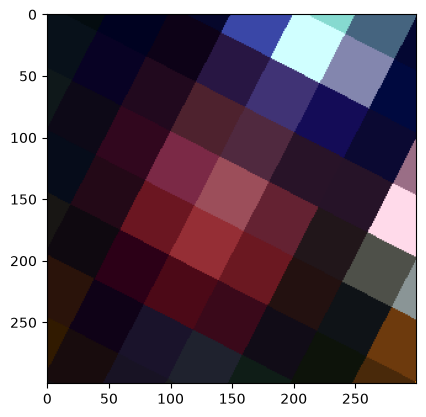

In [33]:
import matplotlib.pyplot as plt
import numpy as np

red_data = red_images[0][0].data
green_data = green_images[0][0].data
blue_data = blue_images[0][0].data

def normalize_channel(channel_data: np.ndarray) -> np.ndarray:
    min_val = channel_data.min()
    max_val = channel_data.max()
    channel_data = (channel_data - min_val) / (max_val - min_val) * 255
    return channel_data.astype(np.uint8)    

if red_data.shape != blue_data.shape:
    raise ValueError("Shapes are different dude")

rgb_data = np.dstack((normalize_channel(red_data), normalize_channel(green_data), normalize_channel(blue_data)))
    
plt.imshow(rgb_data)

In [27]:
# save as image
from PIL import Image
image = Image.fromarray(rgb_data)
image.save("sh2-71_rgb.png")